# CHILLED - Chiller Health Indicator Learning & Early Detection

In [303]:
import polars as pl
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [304]:
df = pl.read_csv('output/chiller_data.csv')
print(df.shape)
print(df.schema)
root_df = df

(2508, 46)
Schema({'date': String, 'chiller_id': String, 'timestamp': String, 'refrigerant_leak_status': String, 'opening_of_vane': Float64, 'opening_hot_gas_bypass_valve': Float64, 'opening_of_2nd_vane': Float64, 'opening_of_high_stage_expansion_valve': Float64, 'opening_of_low_stage_expansion_valve': Float64, 'motor_voltage': Float64, 'motor_current': Float64, 'motor_input': Float64, 'compressor_running_time': Float64, 'compressor_suction_temperature': String, 'compressor_discharge_temperature': String, 'compressor_oil_tank_oil_temperature': Float64, 'compressor_oil_pressure': Float64, 'compressor_oil_level': String, 'compressor_oil_supply_temperature': Float64, 'evaporator_evaporating_pressure': Float64, 'evaporator_evaporating_temperature': Float64, 'evaporator_saturation_temperature': Float64, 'evaporator_approach_temp': Float64, 'evaporator_chilled_water_flow_rate': Float64, 'evaporator_chilled_water_entering_temperature': Float64, 'evaporator_chilled_water_leaving_temperature': 

In [305]:
pl.Config.set_tbl_rows(20)
df.head(15)

date,chiller_id,timestamp,refrigerant_leak_status,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_suction_temperature,compressor_discharge_temperature,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_level,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_liquid_level_side_glass_bottom,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,heat_balance,cop,pct_of_cooling_capacity,pct_of_motor_input,evaporator_metric_24
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""2024-06-05""","""EC0120A""","""00:00""",null,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,null,null,57.9,5.2,null,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,null,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,null,5.52,null,null,null
"""2024-06-05""","""EC0120A""","""09:00""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,null,1225.3,0.0,null,null,null,null,null,null,null,null
"""2024-06-05""","""EC0120B""","""00:00""",null,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,null,null,59.2,0.49,null,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,null,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,null,5.23,null,null,null
"""2024-06-05""","""EC0120B""","""09:00""",null,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,null,null,59.2,4.49,null,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,null,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,null,4.76,null,null,null
"""2024-06-05""","""EC0120C""","""00:00""",null,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,null,null,58.0,0.59,null,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,null,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,null,5.33,null,null,null
"""2024-06-05""","""EC0120C""","""09:00""",null,71.2,0.0,67.6,62.6,37.1,6.6,115.2,1191.0,44240.0,null,null,58.2,0.59,null,45.1,0.23,4.8,3.9,-0.3,702.0,12.7,4.5,8.2,6647.113164,0.85,37.1,37.8,2.7,null,29.6,35.1,5.5,1297.0,8237.297921,0.47,20.1,203.2,null,5.08,null,null,null
"""2024-06-05""","""EC0120D""","""00:00""",null,73.5,0.1,68.1,64.9,35.2,6.6,118.6,1212.0,46445.0,null,null,57.5,0.54,null,44.7,0.23,4.7,3.6,0.3,701.4,13.2,5.0,8.2,6641.431871,0.86,38.0,38.3,3.4,null,29.2,34.9,5.7,1198.0,7885.2194,0.48,21.0,205.9,null,4.98,null,null,null
"""2024-06-05""","""EC0120D""","""09:00""",null,73.5,0.1,67.9,65.3,32.8,6.6,118.8,1215.0,46453.0,null,null,57.5,0.54,null,44.9,0.23,4.8,3.7,0.3,748.0,12.8,5.1,7.7,6650.808314,0.87,38.2,38.4,3.3,null,29.5,35.1,5.6,1220.0,7889.145497,0.49,21.2,217.4,null,4.68,null,null,null
"""2024-06-05""","""EC0120E""","""00:00""",null,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,0.0,null,0.0,null,null,null,null,null,null,null,null


In [306]:
df.describe()

statistic,date,chiller_id,timestamp,refrigerant_leak_status,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_suction_temperature,compressor_discharge_temperature,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_level,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_liquid_level_side_glass_bottom,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,heat_balance,cop,pct_of_cooling_capacity,pct_of_motor_input,evaporator_metric_24
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""count""","""2508""","""2508""","""2508""","""1839""",1607.0,1607.0,1607.0,1607.0,1604.0,1671.0,1607.0,1607.0,1559.0,"""0""","""0""",1607.0,1605.0,"""2""",1605.0,1606.0,1604.0,1604.0,2459.0,1606.0,1606.0,1606.0,2471.0,2460.0,1606.0,1604.0,1605.0,2481.0,"""1""",1606.0,1606.0,2475.0,1607.0,2485.0,1606.0,1605.0,1606.0,"""0""",1606.0,"""2""","""0""","""24"""
"""null_count""","""0""","""0""","""0""","""669""",901.0,901.0,901.0,901.0,904.0,837.0,901.0,901.0,949.0,"""2508""","""2508""",901.0,903.0,"""2506""",903.0,902.0,904.0,904.0,49.0,902.0,902.0,902.0,37.0,48.0,902.0,904.0,903.0,27.0,"""2507""",902.0,902.0,33.0,901.0,23.0,902.0,903.0,902.0,"""2508""",902.0,"""2506""","""2508""","""2484"""
"""mean""",null,null,null,null,74.437772,0.140261,69.383199,69.491867,44.669264,7.020766,117.372222,1180.489172,49955.419949,null,null,58.207716,0.554841,null,44.996573,0.227634,4.126496,3.298211,0.946795,660.480679,13.302677,4.830822,5.500364,4143.824946,0.876164,36.109121,36.623925,1.796372,null,28.541968,33.894085,3.465737,1258.417554,4999.1552,0.519875,19.809875,184.104134,null,5.4784,null,null,null
"""std""",null,null,null,null,3.373344,1.808525,4.76401,29.138334,10.998752,14.773625,4.965425,49.425639,24490.42669,null,null,1.677108,1.22032,null,1.600992,0.053015,0.465814,1.075358,10.137757,33.363716,2.976027,12.520819,11.118173,9164.744913,2.00961,1.200236,2.078188,2.246753,null,0.936305,1.056961,2.701266,71.83696,3925.033645,1.641825,4.496737,55.880966,null,0.282415,null,null,null
"""min""","""2024-06-05""","""EC0120A""","""00:00""","""2028-11-12 09:36:00""",36.6,0.0,27.4,6.8,2.7,6.6,81.5,12.3,3179.0,null,null,44.5,0.43,"""m""",4.5,0.2,2.1,0.23,-13.8,375.2,9.8,3.5,-492.1,-412488.903002,0.0,0.83,2.7,-34.6,""" """,26.6,4.1,-24.6,129.1,-36762.512702,0.24,17.6,2.87,null,4.54,"""5.75""",null,"""0"""
"""25%""",null,null,null,null,72.4,0.0,67.5,65.0,37.3,6.6,116.1,1169.0,46861.0,null,null,57.7,0.49,null,44.9,0.22,3.9,2.9,0.0,637.8,13.0,4.2,0.0,0.0,0.81,35.6,36.2,0.0,null,28.0,33.4,0.0,1239.4,0.0,0.46,19.3,159.8,null,5.3,null,null,null
"""50%""",null,null,null,null,74.3,0.0,69.4,68.1,41.9,6.6,117.2,1187.0,49332.2,null,null,58.4,0.52,null,45.0,0.22,4.2,3.3,0.8,648.6,13.3,4.5,8.4,6458.752887,0.82,36.2,36.7,2.2,null,28.6,33.9,5.1,1292.5,7518.12933,0.46,19.7,198.6,null,5.52,null,null,null
"""75%""",null,null,null,null,76.4,0.1,71.9,71.7,51.7,6.6,118.3,1200.0,50798.7,null,null,59.0,0.53,null,45.1,0.23,4.4,3.6,1.2,677.92,13.5,4.8,8.9,6697.30254,0.84,36.7,37.3,2.9,null,29.0,34.4,5.

The columns that are almost only null values are droped entirely

In [307]:
all_null_cols = [
    'compressor_suction_temperature',
    'compressor_discharge_temperature',
    'compressor_oil_level',
    'condensor_liquid_level_side_glass_bottom',
    'heat_balance',
    'pct_of_cooling_capacity',
    'pct_of_motor_input',
    'evaporator_metric_24'
]

df = df.drop(all_null_cols)

## Formatting

For easier handling, some columns are transformed

- timestamps: instead of two columns for data and time, only one timestamp column
- chiller_id: the last letter of the string is enough to identify the chiller unit
- refrigerant_leak_status: instead of "OK" string, column is translated to 0 and 1

In [308]:
df = df.with_columns(
    (pl.col('date') + " " + pl.col('timestamp'))
    .str.to_datetime("%Y-%m-%d %H:%M")
    .alias("timestamp")
)

df = df.drop('date')

In [309]:
df["chiller_id"].value_counts()

# Verifies that all measurements translate to only 6 units, only use the last letter for identification

chiller_id,count
str,u32
"""EC0120F""",418
"""EC0120C""",418
"""EC0120B""",418
"""EC0120E""",418
"""EC0120A""",418
"""EC0120D""",418


In [310]:
df = df.with_columns(
    pl.col('chiller_id').str.tail(1)
)

In [311]:
df = df.with_columns(
    pl.when(pl.col('refrigerant_leak_status') == "OK")
        .then(1)
        .otherwise(0)
        .alias('is_refrigerant_leak_healthy (bool)')
)

df = df.drop('refrigerant_leak_status')

In [312]:
df.head()

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
"""A""",2024-06-05 00:00:00,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,57.9,5.2,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,5.52,0
"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
"""B""",2024-06-05 00:00:00,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,59.2,0.49,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,5.23,0
"""B""",2024-06-05 09:00:00,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,59.2,4.49,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,4.76,0
"""C""",2024-06-05 00:00:00,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,58.0,0.59,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,5.33,0


## Columns with approx 900 null values

The `df.head()` output showed, that there are quite a few rows that have approximately 900 null values. Let's further explore if these null values all ocur within the same rows, or if they are spread to different rows.

In [313]:
df.null_count()

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,901,901,901,901,904,837,901,901,949,901,903,903,902,904,904,49,902,902,902,37,48,902,904,903,27,902,902,33,901,23,902,903,902,902,0


In [314]:
# Cols mostly affected by the many nulls issue

null_cols = [
    'opening_of_vane',
    'opening_hot_gas_bypass_valve',
    'opening_of_2nd_vane',
    'opening_of_high_stage_expansion_valve',
    'motor_current',
    'motor_input',
    'compressor_running_time',
    'compressor_oil_tank_oil_temperature',
    'compressor_oil_pressure',
    'compressor_oil_supply_temperature',
    'evaporator_evaporating_pressure',
    'evaporator_evaporating_temperature',
    'evaporator_saturation_temperature',
    'evaporator_chilled_water_flow_rate',
    'evaporator_chilled_water_entering_temperature',
    'evaporator_chilled_water_leaving_temperature',
    'condensor_condensing_pressure',
    'condensor_consensed_liquid_temperature',
    'condensor_saturated_temeprature',
    'condensor_cooling_water_entering_temperature',
    'condensor_cooling_water_leaving_temperature',
    'condensor_cooling_water_flow_rate',
    'economizer_economizer_pressure',
    'economizer_saturated_temperature',
    'economizer_liquid_level',
    'cop'
]

# Are the null masks identical across all these columns?
masks = df.select([pl.col(c).is_null().alias(c) for c in null_cols])

# rows where ALL are null vs rows where ANY is null
summary = df.select(
    n_all_null = pl.all_horizontal(pl.col(c).is_null() for c in null_cols).sum(),
    n_any_null = pl.any_horizontal(pl.col(c).is_null() for c in null_cols).sum(),
)
print(summary)

shape: (1, 2)
┌────────────┬────────────┐
│ n_all_null ┆ n_any_null │
│ ---        ┆ ---        │
│ u32        ┆ u32        │
╞════════════╪════════════╡
│ 894        ┆ 966        │
└────────────┴────────────┘


Many rows indeed have all null values in our specified columns. It seems like the null values at least are concentrated on the smallest possible number of rows (even though it's still a lot of rows). Let's further explore what the rows look like that have a lot of null values and if the rows might still carry insights. 

In [315]:
dup = df.drop(["timestamp", "chiller_id"])
dup = dup.filter(dup.is_duplicated())
dup_counts = dup.group_by(pl.all()).len().sort("len", descending=True)
dup_counts.select('len', pl.exclude('len'))

len,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
485,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
224,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
45,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,1.0,null,null,0.0,null,0.0,null,null,null,null,0
41,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
21,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0
19,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
16,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
14,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,1.0,null,null,0.0,null,0.0,null,null,null,null,1
6,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0


The vast majority of duplicate rows are the ones where the identified columns are null. Also when a row almost contains only null values, the entry doesn't carry enough information and is assumed to be an empty record actually. The rows with a lot of null values are for now added to a mask for later dropping.

In [316]:
null_mask = pl.all_horizontal(pl.col(c).is_null() for c in null_cols)

There are still a few cols that have a lot of null values

In [317]:
df.filter(~null_mask).describe()

statistic,chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""1614""","""1614""",1607.0,1607.0,1607.0,1607.0,1604.0,1606.0,1607.0,1607.0,1559.0,1607.0,1605.0,1605.0,1606.0,1604.0,1604.0,1609.0,1606.0,1606.0,1606.0,1612.0,1597.0,1606.0,1604.0,1605.0,1613.0,1606.0,1606.0,1611.0,1607.0,1614.0,1606.0,1605.0,1606.0,1606.0,1614.0
"""null_count""","""0""","""0""",7.0,7.0,7.0,7.0,10.0,8.0,7.0,7.0,55.0,7.0,9.0,9.0,8.0,10.0,10.0,5.0,8.0,8.0,8.0,2.0,17.0,8.0,10.0,9.0,1.0,8.0,8.0,3.0,7.0,0.0,8.0,9.0,8.0,8.0,0.0
"""mean""",null,"""2024-12-29 21:49:57.769516""",74.437772,0.140261,69.383199,69.491867,44.669264,7.037796,117.372222,1180.489172,49955.419949,58.207716,0.554841,44.996573,0.227634,4.126496,3.298211,1.446967,660.480679,13.302677,4.830822,8.43139,6383.099166,0.876164,36.109121,36.623925,2.725232,28.541968,33.894085,5.324457,1258.417554,7696.964481,0.519875,19.809875,184.104134,5.4784,0.975217
"""std""",null,null,3.373344,1.808525,4.76401,29.138334,10.998752,15.069563,4.965425,49.425639,24490.42669,1.677108,1.22032,1.600992,0.053015,0.465814,1.075358,12.505081,33.363716,2.976027,12.520819,12.83736,10728.798065,2.00961,1.200236,2.078188,2.294167,0.936305,1.056961,1.144481,71.83696,1716.701054,1.641825,4.496737,55.880966,0.282415,0.155512
"""min""","""A""","""2024-06-05 00:00:00""",36.6,0.0,27.4,6.8,2.7,6.6,81.5,12.3,3179.0,44.5,0.43,4.5,0.2,2.1,0.23,-13.8,375.2,9.8,3.5,-492.1,-412488.903002,0.0,0.83,2.7,-34.6,26.6,4.1,-24.6,129.1,-36762.512702,0.24,17.6,2.87,4.54,0.0
"""25%""",null,"""2024-07-25 09:00:00""",72.4,0.0,67.5,65.0,37.3,6.6,116.1,1169.0,46861.0,57.7,0.49,44.9,0.22,3.9,2.9,0.8,637.8,13.0,4.2,8.4,6473.152425,0.81,35.6,36.2,2.2,28.0,33.4,5.2,1239.4,7552.369515,0.46,19.3,159.8,5.3,1.0
"""50%""",null,"""2025-03-15 00:00:00""",74.3,0.0,69.4,68.1,41.9,6.6,117.2,1187.0,49332.2,58.4,0.52,45.0,0.22,4.2,3.3,1.1,648.6,13.3,4.5,8.8,6638.152425,0.82,36.2,36.7,2.6,28.6,33.9,5.4,1292.5,7885.450346,0.46,19.7,198.6,5.52,1.0
"""75%""",null,"""2025-05-11 00:00:00""",76.4,0.1,71.9,71.7,51.7,6.6,118.3,1200.0,50798.7,59.0,0.53,45.1,0.23,4.4,3.6,1.4,677.92,13.5,4.8,9.0,6788.048499,0.84,36.7,37.3,3.3,29.0,34.4,5.6,1297.8,8104.988453,0.47,20.1,205.6,5.67,1.0
"""max""","""F""","""2025-06-30 09:00:00""",83.9,72.2,81.0,739.0,100.0,606.0,196.9,1243.0,495779.0,62.4,49.0,59.6,2.2,5.5,36.5,501.9,768.8,131.3,506.0,126.7,94009.644342,81.0,38.8,63.2,31.9,39.5,36.5,7.9,1361.7,11527.431871,47.0,196.5,2000.8,6.32,1.0


Let's take a look at the null value count per row and check how many rows are still affected by the issue

In [318]:
n_nulls_df = df.filter(~null_mask).with_columns(
    pl.sum_horizontal(pl.all().is_null()).alias('n_nulls')
)


display(n_nulls_df.select("n_nulls", pl.exclude("n_nulls")).sort('n_nulls', descending=True).head(20))
display(n_nulls_df.select("n_nulls", pl.exclude("n_nulls")).sort('n_nulls', descending=True).group_by("n_nulls").len())



n_nulls,chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
28,"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
28,"""A""",2024-07-23 00:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.28,1
27,"""A""",2024-07-24 00:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.28,0
27,"""D""",2025-04-03 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.11,1
27,"""D""",2025-04-22 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,1293.74,0.0,null,null,null,null,0
27,"""E""",2025-04-29 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,1246.0,0.0,null,null,null,null,0
17,"""A""",2025-03-14 00:00:00,70.6,0.1,64.7,67.4,36.2,6.6,117.2,1147.0,49077.0,58.5,0.53,null,null,null,null,0.3,null,null,null,8.4,6286.226328,null,null,null,2.6,null,null,5.9,null,7484.551963,null,null,null,null,1
17,"""B""",2025-05-02 00:00:00,77.3,0.0,72.1,68.8,54.7,6.6,114.7,1166.0,51293.0,59.1,0.49,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
11,"""B""",2025-03-14 09:00:00,null,null,null,null,null,null,null,null,null,null,null,44.7,0.22,4.2,3.2,2.1,646.7,13.7,5.5,8.3,6282.69746,0.83,36.1,36.9,4.1,28.3,33.4,4.8,1226.2,7206.540416,0.46,19.7,119.8,5.41,1


n_nulls,len
u32,u32
28,2
27,4
17,2
11,1
2,4
1,86
0,1515


There a few more rows with rather sparse data. We'll also drop the rwos that have more than 2 missing values, since it's not that many rows and there values don't seem out of the ordinary. Accordingly the null mask is adjusted.

In [319]:
null_mask = pl.sum_horizontal(pl.all().is_null()) > 2

Now before we drop those rows entirely we want to take a closer look at these rows to maybe identify a pattern.

In [320]:
df.filter(null_mask) \
  .select(["timestamp", "chiller_id"]) \
  .group_by("chiller_id") \
  .len() \
  .sort("chiller_id")

chiller_id,len
str,u32
"""A""",136
"""B""",159
"""C""",133
"""D""",133
"""E""",145
"""F""",197


It's not only one chiller unit that is affected by the null values. All of the units experience the same problems. Let's take a further look at which time of day the null values mostly appear

In [324]:
(
    df.filter(null_mask)
    .group_by(pl.col("timestamp").dt.time())
    .agg(pl.len().alias("count"))
    .with_columns(
        pct = pl.col("count") / pl.col("count").sum() * 100
    )
)

timestamp,count,pct
time,u32,f64
09:00:00,805,89.147287
00:00:00,98,10.852713


This is quite interesting: Almost 90% of null values are present at the 9am measurement cycle. Next, we'll take a look if the null values appear in specific time periods.

In [343]:
df.group_by("timestamp", "chiller_id").len().sort("len", descending=True)

timestamp,chiller_id,len
datetime[μs],str,u32
2025-03-14 00:00:00,"""B""",2
2025-03-14 09:00:00,"""E""",2
2025-03-14 00:00:00,"""D""",2
2025-03-14 00:00:00,"""E""",2
2025-03-14 09:00:00,"""D""",2
2025-03-14 09:00:00,"""C""",2
2025-03-14 00:00:00,"""C""",2
2025-03-14 09:00:00,"""A""",2
2025-03-14 09:00:00,"""B""",2


In [328]:
null_values_plt = (
    df.filter(null_mask)
    .group_by(pl.col("timestamp").dt.date().alias("date"), "chiller_id")
    .len()
)

px.line(
    null_values_plt.sort("date"),
    x="date", y="len",
    color="chiller_id"
)

In [282]:
df

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
"""A""",2024-06-05 00:00:00,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,57.9,5.2,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,5.52,0
"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
"""B""",2024-06-05 00:00:00,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,59.2,0.49,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,5.23,0
"""B""",2024-06-05 09:00:00,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,59.2,4.49,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,4.76,0
"""C""",2024-06-05 00:00:00,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,58.0,0.59,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,5.33,0
"""C""",2024-06-05 09:00:00,71.2,0.0,67.6,62.6,37.1,6.6,115.2,1191.0,44240.0,58.2,0.59,45.1,0.23,4.8,3.9,-0.3,702.0,12.7,4.5,8.2,6647.113164,0.85,37.1,37.8,2.7,29.6,35.1,5.5,1297.0,8237.297921,0.47,20.1,203.2,5.08,0
"""D""",2024-06-05 00:00:00,73.5,0.1,68.1,64.9,35.2,6.6,118.6,1212.0,46445.0,57.5,0.54,44.7,0.23,4.7,3.6,0.3,701.4,13.2,5.0,8.2,6641.431871,0.86,38.0,38.3,3.4,29.2,34.9,5.7,1198.0,7885.2194,0.48,21.0,205.9,4.98,0
"""D""",2024-06-05 09:00:00,73.5,0.1,67.9,65.3,32.8,6.6,118.8,1215.0,46453.0,57.5,0.54,44.9,0.23,4.8,3.7,0.3,748.0,12.8,5.1,7.7,6650.808314,0.87,38.2,38.4,3.3,29.5,35.1,5.6,1220.0,7889.145497,0.49,21.2,217.4,4.68,0
"""E""",2024-06-05 00:00:00,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0


For further analysis we are dropping these rows, which leaves us with a dataset of 1605 datapoints and 37 sensor measurments

In [283]:
df = df.filter(~null_mask)

## Visualizations

We now take a closer look at how the data changes over time by individually plotting a line graph for each sensor and both periods. The plots are grouped by component. 

In [20]:
valve_cols = [
    'opening_of_vane',
    'opening_hot_gas_bypass_valve',
    'opening_of_2nd_vane',
    'opening_of_high_stage_expansion_valve',
    'opening_of_low_stage_expansion_valve'
]

motor_cols = [
    'motor_voltage',
    'motor_current',
    'motor_input',
]

compressor_cols = [
    'compressor_running_time',
    'compressor_oil_tank_oil_temperature',
    'compressor_oil_pressure',
    'compressor_oil_supply_temperature',
]

evaporator_cols = [
    'evaporator_evaporating_pressure',
    'evaporator_evaporating_temperature',
    'evaporator_saturation_temperature',
    'evaporator_approach_temp',
    'evaporator_chilled_water_flow_rate',
    'evaporator_chilled_water_entering_temperature',
    'evaporator_chilled_water_leaving_temperature',
    'evaporator_temperature_difference',
    'evaporator_chilling_capacity',
]

condensor_cols = [
    'condensor_condensing_pressure',
    'condensor_consensed_liquid_temperature',
    'condensor_saturated_temeprature',
    'condensor_approach_temp_cond_lq_temp_leaving_temp',
    'condensor_cooling_water_entering_temperature',
    'condensor_cooling_water_leaving_temperature',
    'condensor_temperature_difference_cooling_water',
    'condensor_cooling_water_flow_rate',
    'condensor_heat_capacity',
]

economizer_cols = [
    'economizer_economizer_pressure',
    'economizer_saturated_temperature',
    'economizer_liquid_level',
]

other_cols = [
    'cop',
    'is_refrigerant_leak_healthy (bool)'
]

sensor_groups = {
    "valves": valve_cols,
    "motor": motor_cols,
    "compressor": compressor_cols,
    "evaporator": evaporator_cols,
    "condensor": condensor_cols,
    "economizer": economizer_cols,
    "other": other_cols,
}

In [128]:
def plot_group(df, name, cols):
    # change the filter condition to view different chiller units (all at once are hard to grasp)
    long = df.filter(pl.col("chiller_id").is_in(["A", "B", "C", "D", "E", "F"])) \
        .unpivot(
            index=["timestamp", "chiller_id"],
            on=cols,
            variable_name="sensor",
            value_name="value",
        )
    
    long = long.with_columns(
        pl.when(pl.col("timestamp") < pl.datetime(2024, 9, 1))
        .then(pl.lit("JUN-AUG"))
        .otherwise(pl.lit("APR-MAY"))
        .alias("period")
    )
    
    n = len(cols)
    fig = px.line(
        long.sort("timestamp").to_pandas(),
        x="timestamp", y="value",
        facet_row="sensor",
        facet_col="period",
        color="chiller_id",
        facet_row_spacing=min(0.02, 1 / (n * 2)),   # safe for any group size
        height=max(400, 180 * n),
        title=f"{name} sensors",
    )
    
    
    fig.update_yaxes(matches=None)  
    
    fig.update_xaxes(matches=None)
    fig.update_xaxes(range=["2024-06-01", "2024-08-31"], col=1)
    fig.update_xaxes(range=["2025-03-01", "2025-05-31"], col=2)# independent y-scales
    
    row_anns = [a for a in fig.layout.annotations if a.textangle == 90]

    for i, a in enumerate(row_anns):
        a.update(
            text=a.text.split("=")[-1],
            font_size=10,
            xshift=15 if i % 2 else 5,   # push every second label further right
        )
    
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
    
    fig.update_layout(margin=dict(t=110))
    
    fig.show()

for name, cols in sensor_groups.items():
    plot_group(df, name, cols)

#### Observations

- Definitely some outliers that coincide
- Some outliers look like they might have been typos, because either off by a power of 10, unsensible from a domain pov or off by one order maybe because numbers are close on input device
- No clearly visible pattern before an outlier occurs
- Some components work have a lot of deviations while others barely change

**How is sensor data caputred? Manual readings executed by humans or digital?**

### Column Correlations
First we'll take a look at only one chiller unit and later at the normalized sensor values of all units

In [22]:
sensor_cols = [c for c, t in df.schema.items() if c not in ("timestamp", "chiller_id") and t in (pl.Float64, pl.Int64)]

corr = df.filter(pl.col("chiller_id") == "C").select(sensor_cols).drop_nulls().corr()

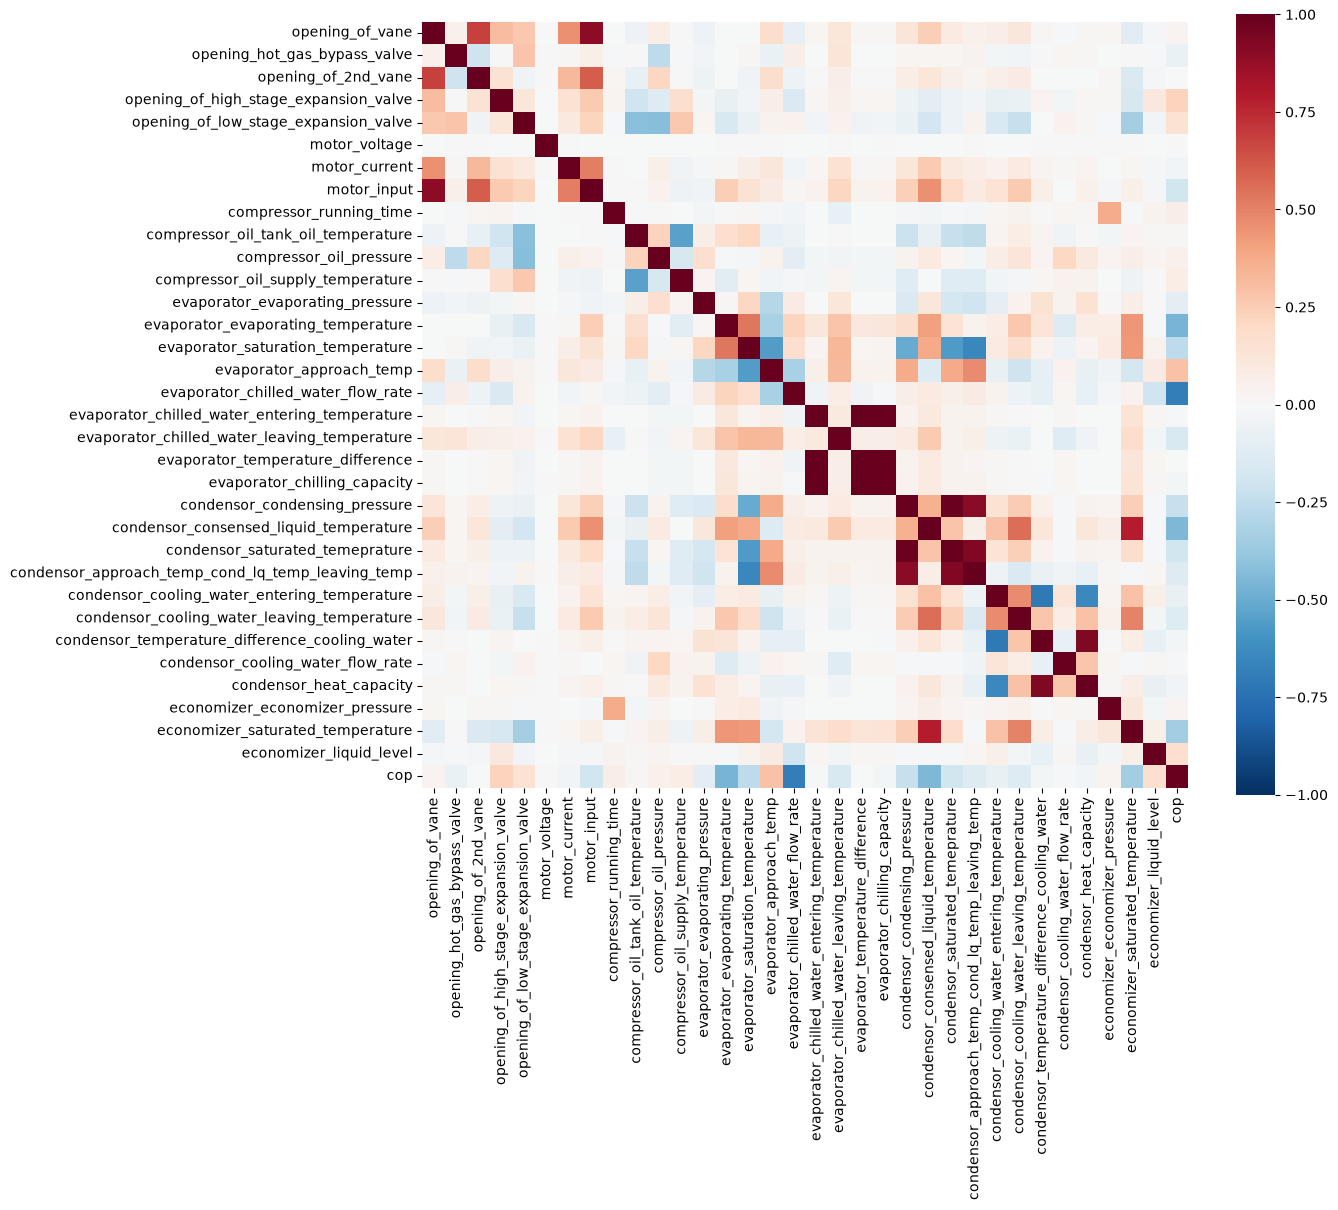

In [23]:
plt.figure(figsize=(14, 12))
sns.heatmap(corr.to_pandas(), xticklabels=sensor_cols, yticklabels=sensor_cols,
            cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True)
plt.tight_layout()

Now we also take a look at the correlations of all units, however by their normalized values, to account for different baselines and operating settings for each chiller unit 

In [24]:
# Normalize values per chiller
z = df.drop_nulls().with_columns([
    ((pl.col(c) - pl.col(c).mean().over("chiller_id"))
        / pl.col(c).std().over("chiller_id")).alias(c)
    for c in sensor_cols
])
z_corr = z.select(sensor_cols).corr()

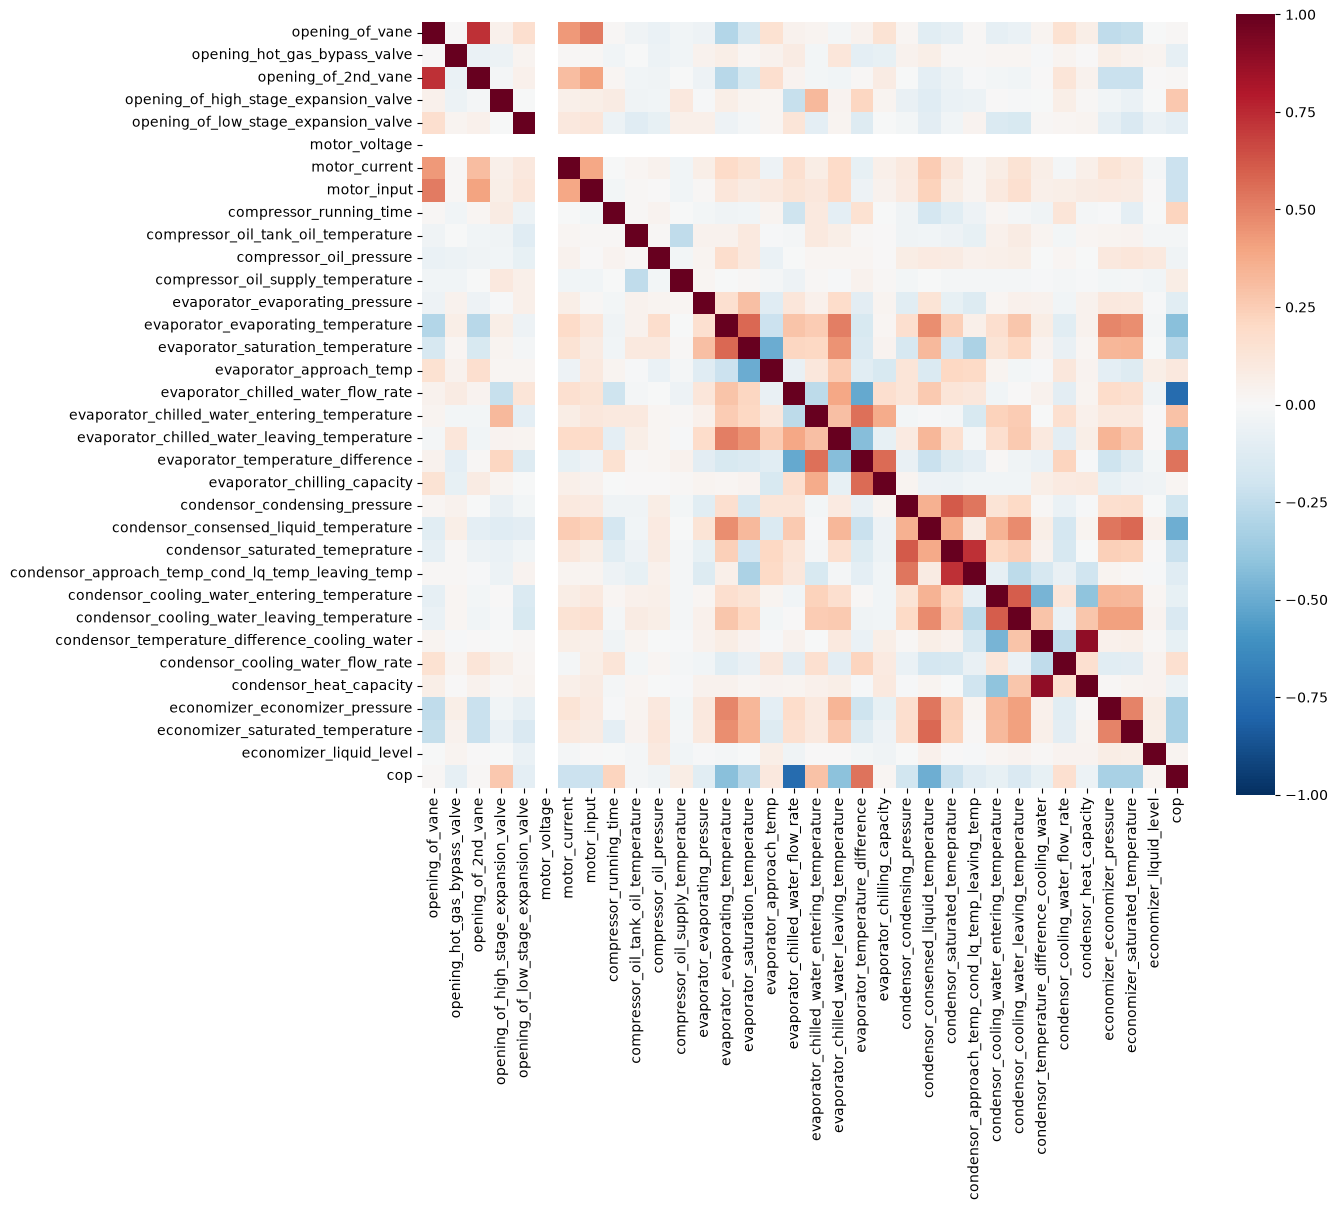

In [25]:
plt.figure(figsize=(14, 12))
sns.heatmap(z_corr.to_pandas(), xticklabels=sensor_cols, yticklabels=sensor_cols,
            cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True)
plt.tight_layout()

Observation: motor voltage is a NaN, probably because it's constant

Let's see which sensors correlate the strongest:

In [26]:
z_corr_unpv = (
    z_corr
        .with_columns(pl.Series("sensor_a", sensor_cols))
        .unpivot(index="sensor_a", variable_name="sensor_b", value_name="corr")
        .filter(pl.col("sensor_a") != pl.col("sensor_b"))
        .filter(pl.col("sensor_a") > pl.col("sensor_b")) # deduplicate rows
        .drop_nans("corr")
        .with_columns(pl.col("corr").abs().alias("abs_corr"))
        .sort("abs_corr", descending=True)
)

with pl.Config(tbl_rows=45, tbl_cols=-1, fmt_str_lengths=100):
    display(z_corr_unpv)

sensor_a,sensor_b,corr,abs_corr
str,str,f64,f64
"""condensor_temperature_difference_cooling_water""","""condensor_heat_capacity""",0.883454,0.883454
"""evaporator_chilled_water_flow_rate""","""cop""",-0.771252,0.771252
"""opening_of_vane""","""opening_of_2nd_vane""",0.728653,0.728653
"""condensor_saturated_temeprature""","""condensor_approach_temp_cond_lq_temp_leaving_temp""",0.727349,0.727349
"""condensor_saturated_temeprature""","""condensor_condensing_pressure""",0.616353,0.616353
"""condensor_cooling_water_leaving_temperature""","""condensor_cooling_water_entering_temperature""",0.608225,0.608225
"""evaporator_saturation_temperature""","""evaporator_evaporating_temperature""",0.572807,0.572807
"""economizer_saturated_temperature""","""condensor_consensed_liquid_temperature""",0.572047,0.572047
"""evaporator_temperature_difference""","""evaporator_chilling_capacity""",0.567479,0.567479


## Outliers

Next we will take a closer look at the outliers in the data set to check which might indicate an operating irregularity. We'll use Mean Absolute Deviation (MAD) and IQR for detecting outliers. 

In [27]:
long_df = df.unpivot(index=["timestamp", "chiller_id"], variable_name="sensor")

In [129]:
long_df

timestamp,chiller_id,sensor,value,component
datetime[μs],str,str,f64,str
2024-06-05 00:00:00,"""A""","""opening_of_vane""",70.5,"""valves"""
2024-06-05 00:00:00,"""B""","""opening_of_vane""",81.8,"""valves"""
2024-06-05 09:00:00,"""B""","""opening_of_vane""",77.7,"""valves"""
2024-06-05 00:00:00,"""C""","""opening_of_vane""",74.4,"""valves"""
2024-06-05 09:00:00,"""C""","""opening_of_vane""",71.2,"""valves"""
2024-06-05 00:00:00,"""D""","""opening_of_vane""",73.5,"""valves"""
2024-06-05 09:00:00,"""D""","""opening_of_vane""",73.5,"""valves"""
2024-06-05 00:00:00,"""F""","""opening_of_vane""",78.6,"""valves"""
2024-06-06 00:00:00,"""A""","""opening_of_vane""",71.7,"""valves"""


In [28]:
# Set selectivness of the IQR and MAD filter
mad_threshold = 4
iqr_threshold = 2

In [29]:
sensor_to_component = {
    sensor: component
    for component, cols in sensor_groups.items()
    for sensor in cols
}

long_df = long_df.with_columns(
    pl.col("sensor").replace(sensor_to_component).alias("component")
).drop_nulls()

In [30]:
# Calculate MAD for each unit, sensor pair

g = ["chiller_id", "sensor"]

outlier_df = (
    long_df.with_columns(median = pl.col("value").median().over(g))
    .with_columns(mad = (pl.col("value") - pl.col("median")).abs().median().over(g))
    .with_columns(rz = (pl.col("value") - pl.col("median")).abs() / (1.4826 * pl.col("mad")))
    .with_columns((pl.col("rz").is_not_nan() & (pl.col("mad") != 0) & (pl.col("rz") >= mad_threshold)).alias("mad_outlier"))
)

In [31]:
# Calculate IQR
outlier_df = (
    outlier_df.with_columns(
        q1 = pl.col("value").quantile(0.25).over(g),
        q3 = pl.col("value").quantile(0.75).over(g),
    ).with_columns(
        iqr = pl.col("q3") - pl.col("q1")
    ).with_columns(
        iqr_outlier = (pl.col("value") < pl.col("q1") - iqr_threshold * pl.col("iqr")) | (pl.col("value") > pl.col("q3") + iqr_threshold * pl.col("iqr"))
    )
)

In [32]:
combined_outlier_df = outlier_df.filter(pl.col("mad_outlier") & pl.col("iqr_outlier"))

In [33]:
combined_outlier_df

timestamp,chiller_id,sensor,value,component,median,mad,rz,mad_outlier,q1,q3,iqr,iqr_outlier
datetime[μs],str,str,f64,str,f64,f64,f64,bool,f64,f64,f64,bool
2024-06-13 00:00:00,"""C""","""opening_of_vane""",62.8,"""valves""",74.0,0.8,9.442871,true,72.9,74.7,1.8,true
2024-06-13 09:00:00,"""C""","""opening_of_vane""",63.7,"""valves""",74.0,0.8,8.684069,true,72.9,74.7,1.8,true
2024-06-14 00:00:00,"""C""","""opening_of_vane""",36.6,"""valves""",74.0,0.8,31.532443,true,72.9,74.7,1.8,true
2024-06-25 00:00:00,"""C""","""opening_of_vane""",62.8,"""valves""",74.0,0.8,9.442871,true,72.9,74.7,1.8,true
2024-07-02 00:00:00,"""A""","""opening_of_vane""",78.0,"""valves""",71.0,1.1,4.292214,true,69.9,72.1,2.2,true
2024-07-14 09:00:00,"""C""","""opening_of_vane""",63.4,"""valves""",74.0,0.8,8.937003,true,72.9,74.7,1.8,true
2024-07-30 09:00:00,"""C""","""opening_of_vane""",63.4,"""valves""",74.0,0.8,8.937003,true,72.9,74.7,1.8,true
2024-08-17 09:00:00,"""C""","""opening_of_vane""",69.2,"""valves""",74.0,0.8,4.046945,true,72.9,74.7,1.8,true
2024-08-20 09:00:00,"""A""","""opening_of_vane""",62.8,"""valves""",71.0,1.1,5.028022,true,69.9,72.1,2.2,true


In [79]:
# Dates with the most outliers
plt_df = combined_outlier_df.group_by((pl.col("timestamp").dt.date()).alias("date"), "chiller_id").len().sort("chiller_id")

fig = px.bar(plt_df, x="date", y="len", color="chiller_id", title="Outliers per day by chiller", height=600)
fig.update_xaxes(type="date", rangebreaks=[dict(bounds=["2024-09-01", "2025-02-27"])])

fig.show()

In [35]:
# Dates with the most outliers
plt_df = combined_outlier_df.group_by((pl.col("timestamp").dt.hour().cast(pl.Utf8) + ":00").alias("time"), "chiller_id").len().sort("time", "chiller_id")

fig = px.bar(plt_df, x="time", y="len", color="chiller_id", title="Outliers per hour by chiller", height=400)
fig.update_xaxes(type="category")

fig.show()

In [36]:
# Dates with the most outliers
plt_df = combined_outlier_df.group_by("chiller_id", "component").len().sort("chiller_id", "component")

fig = px.bar(plt_df, x="chiller_id", y="len", color="component", title="Outliers per chiller", height=400)
fig.update_xaxes(type="category")

fig.show()

In [37]:
# Dates with the most outliers
plt_df = (
    combined_outlier_df.group_by("component", "chiller_id")
    .len()
    .with_columns(pl.col("len").sum().over("component").alias("total_outliers"))
    .sort("chiller_id")
    .sort("total_outliers", descending=True)
)

fig = px.bar(plt_df, x="component", y="len", color="chiller_id", title="Outliers per component", height=400)
fig.update_xaxes(type="category")

fig.show()

In [80]:
daily_counts = combined_outlier_df.group_by("timestamp").len()
px.histogram(daily_counts, x="len").show()

display(daily_counts.sort("len", descending=True).head(10))

daily_counts = combined_outlier_df.group_by(pl.col("timestamp").dt.date()).len()
px.histogram(daily_counts, x="len").show()

display(daily_counts.sort("len", descending=True).head(10))

timestamp,len
datetime[μs],u32
2025-04-27 00:00:00,22
2024-06-11 00:00:00,21
2024-06-14 00:00:00,18
2024-08-20 09:00:00,16
2024-06-13 00:00:00,14
2024-06-25 00:00:00,13
2025-05-15 00:00:00,13
2025-03-13 00:00:00,12
2024-06-13 09:00:00,11


timestamp,len
date,u32
2024-06-11,26
2024-06-13,25
2025-04-27,22
2024-06-14,19
2024-08-20,16
2024-06-25,16
2025-05-15,13
2025-03-13,12
2025-03-01,12


In [ ]:
with pl.Config(tbl_rows=60, tbl_cols=-1, fmt_str_lengths=100):
    display(
        combined_outlier_df
        .with_columns((pl.col("q1").cast(pl.Utf8) + " - " + pl.col("q3").cast(pl.Utf8)).alias("q1_q3_range"))
        .with_columns(
            pl.col("timestamp").len().over("timestamp").alias("outliers_per_day"),
        )
        .drop(["mad", "rz", "q1", "q3", "iqr", "mad_outlier", "iqr_outlier"])
        .sort(["outliers_per_day", "sensor", "chiller_id"], descending=[True, False, False])
        .head(60)
    )

#### Observations
Process
- MAD isn't ideal for values that are very consistent and then only change strongly once
- Mixed with IQR it produces better results, but maybe it's still a bit noisy

Data
- There are a few dates with especially high numbers of outliers, such as 2024-06-11, 2024-06-13, 2025-04-27
- Components with the most outliers are condensor and compressor
- most outliers are recorded at midnight

## PCA
Next we're doing a pca on our sensor data to explore which measures have the most impact on variance

In [83]:
X_df = df.select(sensor_cols).drop_nulls()
X = X_df.to_numpy()

In [84]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
scores = pca.fit_transform(X_scaled)  

In [95]:
print("Variance captured by the PCs:")
print(pca.explained_variance_ratio_)

print("\nCumulative variance captured by the PCs:")
print(np.cumsum(pca.explained_variance_ratio_))

Variance captured by the PCs:
[1.18298040e-01 9.94529098e-02 7.47214272e-02 7.15261592e-02
 5.06207838e-02 4.80493944e-02 3.74218892e-02 3.53370726e-02
 3.38180438e-02 3.15016947e-02 3.01530786e-02 3.00291809e-02
 2.94996218e-02 2.94170689e-02 2.88752307e-02 2.83451370e-02
 2.77106573e-02 2.66588077e-02 2.50747923e-02 2.44400707e-02
 2.16705815e-02 2.07850621e-02 1.84523839e-02 1.71654516e-02
 1.50249941e-02 1.01333615e-02 7.34609321e-03 4.63009809e-03
 2.96688363e-03 8.41470480e-04 2.05133951e-05 9.89826817e-06
 1.96761113e-06 1.80494118e-07]

Cumulative variance captured by the PCs:
[0.11829804 0.21775095 0.29247238 0.36399854 0.41461932 0.46266871
 0.5000906  0.53542768 0.56924572 0.60074741 0.63090049 0.66092967
 0.6904293  0.71984636 0.7487216  0.77706673 0.80477739 0.8314362
 0.85651099 0.88095106 0.90262164 0.9234067  0.94185909 0.95902454
 0.97404953 0.98418289 0.99152899 0.99615909 0.99912597 0.99996744
 0.99998795 0.99999785 0.99999982 1.        ]


#### Observations
- There are quite many modes to the data
- However there are also a few dependencies between the measurements: The last 14 PCs only carry about 10% of the variance

In [114]:
n_pcs = 10
scores_df = pl.DataFrame(scores[:, :n_pcs], schema=[f"PC{x+1}" for x in range(n_pcs)])

loadings = (
    pl.DataFrame(pca.components_[:n_pcs].T, schema=[f"PC{x+1}" for x in range(n_pcs)])
    .with_columns(pl.Series("sensor", sensor_cols))
)

In [127]:
pc = "PC7"

with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=100):
    display(
        loadings
        .select("sensor", pc)
        .with_columns(contribution = pl.col(pc) ** 2)
        .sort("contribution", descending=True)
        .with_columns(cumulative = pl.col("contribution").cum_sum())
    )

sensor,PC7,contribution,cumulative
str,f64,f64,f64
"""economizer_economizer_pressure""",0.669821,0.44866,0.44866
"""compressor_running_time""",0.653098,0.426536,0.875196
"""condensor_cooling_water_entering_temperature""",-0.171,0.029241,0.904437
"""condensor_cooling_water_leaving_temperature""",-0.135901,0.018469,0.922906
"""evaporator_chilled_water_flow_rate""",0.118693,0.014088,0.936994
"""economizer_liquid_level""",0.091621,0.008394,0.945389
"""compressor_oil_tank_oil_temperature""",-0.091216,0.00832,0.953709
"""cop""",-0.084943,0.007215,0.960924
"""evaporator_evaporating_temperature""",0.076526,0.005856,0.96678


In [117]:
# sort rows by sensor name, then split labels from the numeric matrix
loadings_sorted = loadings.sort("sensor")

pc_names = [f"PC{i+1}" for i in range(n_pcs)]
L = loadings_sorted.select(pc_names).to_numpy()      # numeric only, for the image
y_sensors = loadings_sorted["sensor"].to_list()      # labels, in the sorted order

zmax = abs(L).max()

fig = px.imshow(
    L,
    x=pc_names,
    y=y_sensors,
    color_continuous_scale="RdBu_r", zmin=-zmax, zmax=zmax,
    aspect="auto", height=900,
    title="PCA loadings",
)
fig.show()

#### Observation
- PC1 is strongly associated with evaporator chilling capacity
- PC4 is strongly associated with condensor water temperatures
- PC7 is strongly associated with economizer pressure and compressor running time